In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(
    "../data/raw/oil_price.csv",
    parse_dates=["observation_date"],
    na_values=["."],
)
df = df.rename(columns={"observation_date": "date", "DCOILWTICO": "price"})
df.head()

,date,price
0,2021-10-06,77.66
1,2021-10-07,78.46
2,2021-10-08,79.55
3,2021-10-11,80.64
4,2021-10-12,80.75


In [2]:
df.info()
print(df.shape)
print("date range:", df["date"].min(), "to", df["date"].max())

<class 'pandas.DataFrame'>
RangeIndex: 1305 entries, 0 to 1304
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   date    1305 non-null   datetime64[us]
 1   price   1248 non-null   float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 20.5 KB
(1305, 2)
date range: 2021-10-06 00:00:00 to 2026-10-06 00:00:00


In [3]:
print(df["price"].describe())
print("missing values:", df["price"].isna().sum())

count    1248.000000
mean       79.651587
std        13.510637
min        55.440000
25%        70.107500
50%        78.185000
75%        86.465000
max       123.640000
Name: price, dtype: float64
missing values: 57


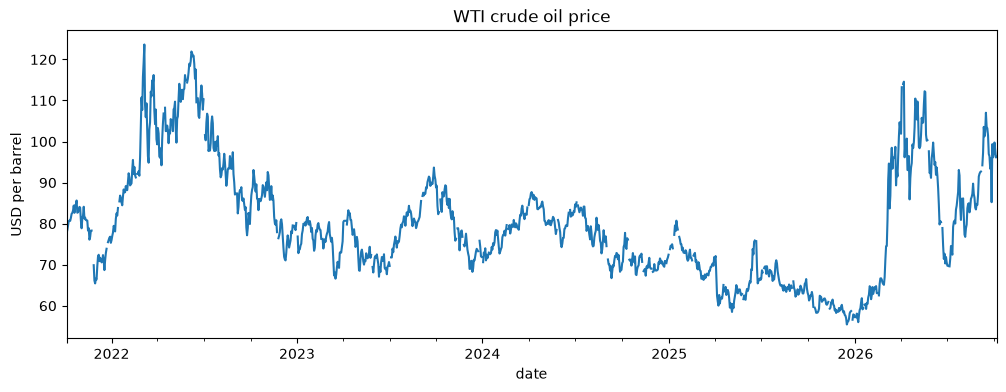

In [4]:
s = df.set_index("date")["price"]
s.plot(figsize=(12, 4), title="WTI crude oil price")
plt.ylabel("USD per barrel")
plt.show()

In [5]:
print("lowest 5:")
print(s.nsmallest(5))
print("biggest daily changes:")
print(s.pct_change().abs().nlargest(5))

lowest 5:
date
2025-12-16    55.44
2026-01-07    56.01
2025-12-17    56.07
2025-12-18    56.22
2025-12-26    56.60
Name: price, dtype: float64
biggest daily changes:
date
2026-09-28    0.165904
2026-04-08    0.160674
2026-03-06    0.122280
2022-03-09    0.119945
2026-03-10    0.115584
Name: price, dtype: float64


In [6]:
gaps = s.index.to_series().diff().dt.days
print(gaps.value_counts().head())
print("longest gap (days):", gaps.max())


date
1.0    1043
3.0     261
Name: count, dtype: int64
longest gap (days): 3.0


In [7]:
for d in ["2026-09-28", "2026-04-08", "2026-03-06"]:
    d = pd.Timestamp(d)
    print(s[d - pd.Timedelta(days=4): d + pd.Timedelta(days=4)])
    print("-" * 30)

date
2026-09-24    95.88
2026-09-25    85.23
2026-09-28    99.37
2026-09-29    96.16
2026-09-30    97.18
2026-10-01    99.77
2026-10-02    97.89
Name: price, dtype: float64
------------------------------
date
2026-04-06    114.01
2026-04-07    114.58
2026-04-08     96.17
2026-04-09     99.62
2026-04-10     98.34
Name: price, dtype: float64
------------------------------
date
2026-03-02    71.13
2026-03-03    74.48
2026-03-04    74.58
2026-03-05    80.88
2026-03-06    90.77
2026-03-09    94.65
2026-03-10    83.71
Name: price, dtype: float64
------------------------------


## Notes on the oil price series

- Trend: price started near 78 in Oct 2021, peaked at 123.64 in March 2022, and fell to a low of about 55 in Dec 2025.
- Problems: 57 missing prices (probably market holidays, no real gaps in dates), and several very large one-day moves in 2026 (Mar 6, Mar 10, Apr 8, Sep 28) of 12-17% that I need to check are real and not data errors.
- To fix before using it: decide how to handle the 57 missing values (forward-fill or drop), flag the extreme days instead of deleting them, then resample to weekly (Day 5).